In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('/content/drive/MyDrive/tugas 1 penambangan data/dataset_peminjaman_perpustakaan.csv')

In [3]:
data.head()

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali
0,PJM-0001,9B,Laki-laki,Komik,1.0,7,1.0,1000,Baik,Terlambat,2026-08-08,2026-08-16
1,PJM-0002,9B,Laki-laki,Buku Pelajaran,1.0,14,0.0,0,Baik,Tepat Waktu,2026-08-27,2026-09-10
2,PJM-0003,8B,Laki-laki,Biografi,3.0,7,1.0,1000,Baik,Terlambat,2026-07-20,2026-07-28
3,PJM-0004,NaN,Perempuan,Ensiklopedia,1.0,7,4.0,4000,Baik,Terlambat,2026-08-13,2026-08-24
4,PJM-0005,7A,Perempuan,novel,1.0,7,2.0,2000,Baik,Terlambat,2026-09-08,2026-09-17


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID_Peminjaman         150 non-null    object 
 1   Kelas_Siswa           145 non-null    object 
 2   Jenis_Kelamin         150 non-null    object 
 3   Kategori_Buku         145 non-null    object 
 4   Jumlah_Buku           146 non-null    float64
 5   Lama_Peminjaman_Hari  147 non-null    object 
 6   Keterlambatan_Hari    145 non-null    float64
 7   Denda_Rp              146 non-null    object 
 8   Kondisi_Buku          147 non-null    object 
 9   Status_Pengembalian   148 non-null    object 
 10  Tanggal_Pinjam        150 non-null    object 
 11  Tanggal_Kembali       150 non-null    object 
dtypes: float64(2), object(10)
memory usage: 14.2+ KB


In [5]:
# Menghitung missing value setiap kolom
data.isnull().sum()

,0
ID_Peminjaman,0
Kelas_Siswa,5
Jenis_Kelamin,0
Kategori_Buku,5
Jumlah_Buku,4
Lama_Peminjaman_Hari,3
Keterlambatan_Hari,5
Denda_Rp,4
Kondisi_Buku,3
Status_Pengembalian,2


In [6]:
# Menampilkan statistik deskriptif data numerik
data.describe()

,Jumlah_Buku,Keterlambatan_Hari
count,146.000000,145.000000
mean,1.835616,2.275862
std,2.910214,6.978621
min,-2.000000,-3.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,35.000000,79.000000


In [7]:
# Menampilkan statistik deskriptif variabel kategorik
data.describe(include=['object'])

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Lama_Peminjaman_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali
count,150,145,150,145,147,146,147,148,150,150
unique,145,10,5,12,7,14,5,4,78,80
top,PJM-0011,9B,Laki-laki,Biografi,7,0,Baik,Terlambat,2026-09-20,2026-10-04
freq,2,33,82,28,78,69,124,75,7,6


In [8]:
# Melihat kategori dan jumlah kemunculannya
data['Jenis_Kelamin'].value_counts(dropna=False)

,count
Jenis_Kelamin,
Laki-laki,82
Perempuan,65
laki laki,1
PEREMPUAN,1
Laki-laki,1


**Data Cleansing**

In [9]:
# Menghapus spasi berlebih
data['Jenis_Kelamin'] = data['Jenis_Kelamin'].str.strip()

# Menyamakan penulisan kategori
data['Jenis_Kelamin'] = data['Jenis_Kelamin'].replace({
    'laki laki': 'Laki-laki',
    'PEREMPUAN': 'Perempuan'
})

# Memeriksa hasil perbaikan
data['Jenis_Kelamin'].value_counts()

,count
Jenis_Kelamin,
Laki-laki,84
Perempuan,66


In [10]:
# Melihat variasi penulisan kategori buku
data['Kategori_Buku'].value_counts(dropna=False)

,count
Kategori_Buku,
Biografi,28
Buku Pelajaran,24
Cerita Anak,24
Novel,24
Komik,20
Ensiklopedia,19
NaN,5
novel,1
NOVEL,1


In [11]:
# Menghapus spasi berlebih
data['Kategori_Buku'] = data['Kategori_Buku'].str.strip()

# Menyamakan huruf kapital setiap kategori
data['Kategori_Buku'] = data['Kategori_Buku'].str.title()

# Memeriksa hasil perbaikan
data['Kategori_Buku'].value_counts(dropna=False)

,count
Kategori_Buku,
Biografi,28
Novel,27
Buku Pelajaran,25
Cerita Anak,24
Komik,21
Ensiklopedia,20
NaN,5


In [12]:
# Memeriksa variasi penulisan kondisi buku
data['Kondisi_Buku'].value_counts(dropna=False)

,count
Kondisi_Buku,
Baik,124
Rusak Ringan,20
NaN,3
rusak ringan,1
BAIK,1
Rusak Berat,1


In [13]:
# Menghapus spasi berlebih
data['Kondisi_Buku'] = data['Kondisi_Buku'].str.strip()

# Menyamakan huruf kapital
data['Kondisi_Buku'] = data['Kondisi_Buku'].str.title()

# Memeriksa hasil perbaikan
data['Kondisi_Buku'].value_counts(dropna=False)

,count
Kondisi_Buku,
Baik,125
Rusak Ringan,21
NaN,3
Rusak Berat,1


In [14]:
# Memeriksa variasi status pengembalian
data['Status_Pengembalian'].value_counts(dropna=False)

,count
Status_Pengembalian,
Terlambat,75
Tepat Waktu,71
NaN,2
terlambat,1
Tepat waktu,1


In [15]:
# Menghapus spasi berlebih
data['Status_Pengembalian'] = data['Status_Pengembalian'].str.strip()

# Menyamakan huruf kapital
data['Status_Pengembalian'] = data['Status_Pengembalian'].str.title()

# Memeriksa hasil perbaikan
data['Status_Pengembalian'].value_counts(dropna=False)

,count
Status_Pengembalian,
Terlambat,76
Tepat Waktu,72
NaN,2


In [16]:
# Memeriksa variasi penulisan kelas siswa
data['Kelas_Siswa'].value_counts(dropna=False)

,count
Kelas_Siswa,
9B,33
8B,30
7B,25
8A,24
7A,16
9A,13
NaN,5
7A,1
8B,1


In [17]:
# Menghapus spasi berlebih
data['Kelas_Siswa'] = data['Kelas_Siswa'].str.strip()

# Menyamakan huruf menjadi kapital
data['Kelas_Siswa'] = data['Kelas_Siswa'].str.upper()

# Memeriksa hasil perbaikan
data['Kelas_Siswa'].value_counts(dropna=False)

,count
Kelas_Siswa,
9B,33
8B,31
7B,26
8A,24
7A,17
9A,14
NaN,5


## 2.2 Impossible Value

In [18]:
# Memeriksa jumlah buku yang tidak masuk akal
data[data['Jumlah_Buku'] <= 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali
25,PJM-0026,7B,Laki-laki,Buku Pelajaran,-2.0,14,1.0,1000,Baik,Terlambat,2026-10-09,2026-10-24
52,PJM-0053,7B,Perempuan,Novel,0.0,7,0.0,0,Rusak Ringan,Tepat Waktu,2026-09-01,2026-09-08


In [19]:
# Mengubah jumlah buku tidak valid menjadi NaN
data.loc[data['Jumlah_Buku'] <= 0, 'Jumlah_Buku'] = np.nan

# Memastikan tidak ada jumlah buku 0 atau negatif
data[data['Jumlah_Buku'] <= 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali


In [20]:
# Memeriksa keterlambatan yang bernilai negatif
data[data['Keterlambatan_Hari'] < 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali
55,PJM-0056,9B,Perempuan,Buku Pelajaran,2.0,14,-3.0,4000,Baik,Terlambat,2026-08-19,2026-09-06


In [21]:
# Mengubah keterlambatan negatif menjadi NaN
data.loc[data['Keterlambatan_Hari'] < 0, 'Keterlambatan_Hari'] = np.nan

# Memastikan tidak ada keterlambatan negatif
data[data['Keterlambatan_Hari'] < 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali


In [22]:
# Mengubah lama peminjaman menjadi numerik
data['Lama_Peminjaman_Hari'] = pd.to_numeric(
    data['Lama_Peminjaman_Hari'],
    errors='coerce'
)

# Memeriksa lama peminjaman yang bernilai 0 atau negatif
data[data['Lama_Peminjaman_Hari'] <= 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali
43,PJM-0044,7B,Laki-laki,Biografi,1.0,-7.0,0.0,0,Baik,Tepat Waktu,2026-09-09,2026-09-16
83,PJM-0084,9A,Laki-laki,Cerita Anak,1.0,0.0,1.0,1000,Rusak Ringan,Terlambat,2026-07-07,2026-07-22


In [23]:
# Mengubah lama peminjaman tidak valid menjadi NaN
data.loc[
    data['Lama_Peminjaman_Hari'] <= 0,
    'Lama_Peminjaman_Hari'
] = np.nan

# Memastikan tidak ada nilai 0 atau negatif
data[data['Lama_Peminjaman_Hari'] <= 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali


In [24]:
# Mengubah kolom denda menjadi numerik
data['Denda_Rp'] = pd.to_numeric(
    data['Denda_Rp'],
    errors='coerce'
)

# Memeriksa denda yang bernilai negatif
data[data['Denda_Rp'] < 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali
65,PJM-0066,8B,Perempuan,Cerita Anak,3.0,10.0,0.0,-2000.0,Baik,Tepat Waktu,2026-08-01,2026-08-11


In [25]:
# Mengubah denda negatif menjadi NaN
data.loc[data['Denda_Rp'] < 0, 'Denda_Rp'] = np.nan

# Memastikan tidak ada denda negatif
data[data['Denda_Rp'] < 0]

,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali


## 2.3 Duplicate Data

In [26]:
# Memeriksa jumlah baris duplikat
print("Jumlah data duplikat:", data.duplicated().sum())

# Menampilkan baris yang merupakan duplikat
data[data.duplicated()]

Jumlah data duplikat: 5


,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali
145,PJM-0011,8A,Laki-laki,Cerita Anak,3.0,7.0,2.0,2000.0,Rusak Ringan,Terlambat,2026-08-28,2026-09-06
146,PJM-0042,9B,Laki-laki,Novel,2.0,14.0,0.0,0.0,Rusak Ringan,Tepat Waktu,2026-08-21,2026-09-04
147,PJM-0077,9B,Laki-laki,Novel,2.0,14.0,0.0,0.0,Baik,Tepat Waktu,2026-09-20,2026-10-04
148,PJM-0111,7B,Laki-laki,Biografi,2.0,10.0,2.0,2000.0,Baik,Terlambat,2026-07-10,2026-07-22
149,PJM-0139,8B,Laki-laki,Komik,1.0,14.0,0.0,0.0,Baik,Tepat Waktu,2026-09-20,2026-10-04


In [27]:
# Menghapus baris duplikat
data = data.drop_duplicates().reset_index(drop=True)

# Memeriksa hasil penghapusan
print("Jumlah data setelah penghapusan:", len(data))
print("Sisa data duplikat:", data.duplicated().sum())

Jumlah data setelah penghapusan: 145
Sisa data duplikat: 0


## 2.4 Outlier

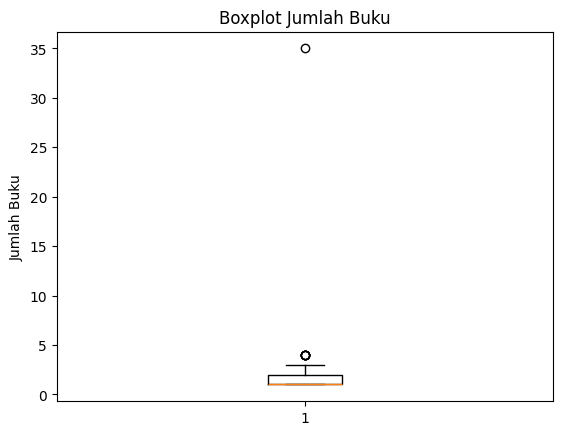

In [28]:
# Membuat boxplot jumlah buku
plt.boxplot(data['Jumlah_Buku'].dropna())

plt.title('Boxplot Jumlah Buku')
plt.ylabel('Jumlah Buku')
plt.show()

In [29]:
# Menghitung batas outlier menggunakan IQR
Q1 = data['Jumlah_Buku'].quantile(0.25)
Q3 = data['Jumlah_Buku'].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

# Menampilkan data yang terdeteksi sebagai outlier
outlier = data[
    (data['Jumlah_Buku'] < batas_bawah) |
    (data['Jumlah_Buku'] > batas_atas)
]

outlier[['ID_Peminjaman', 'Jumlah_Buku']]

Q1: 1.0
Q3: 2.0
IQR: 1.0
Batas bawah: -0.5
Batas atas: 3.5


,ID_Peminjaman,Jumlah_Buku
12,PJM-0013,4.0
23,PJM-0024,4.0
79,PJM-0080,4.0
112,PJM-0113,35.0
118,PJM-0119,4.0
125,PJM-0126,4.0
140,PJM-0141,4.0


In [30]:
# Menandai jumlah buku yang tidak wajar
data.loc[data['Jumlah_Buku'] > 10, 'Jumlah_Buku'] = np.nan

# Memeriksa kembali nilai maksimum
print("Jumlah buku maksimum:", data['Jumlah_Buku'].max())

# Memeriksa apakah masih ada jumlah buku di atas 10
data[data['Jumlah_Buku'] > 10]

Jumlah buku maksimum: 4.0


,ID_Peminjaman,Kelas_Siswa,Jenis_Kelamin,Kategori_Buku,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp,Kondisi_Buku,Status_Pengembalian,Tanggal_Pinjam,Tanggal_Kembali


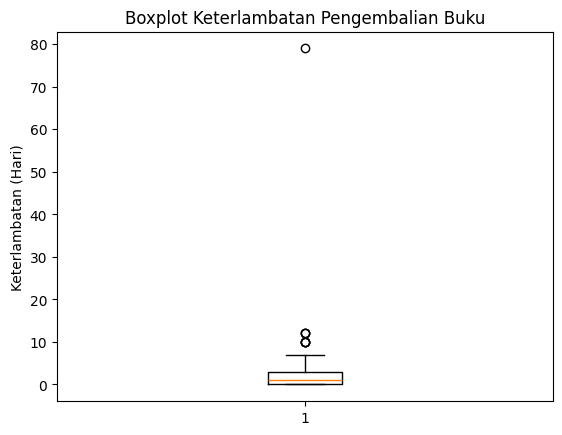

In [31]:
# Membuat boxplot keterlambatan pengembalian
plt.boxplot(data['Keterlambatan_Hari'].dropna())

plt.title('Boxplot Keterlambatan Pengembalian Buku')
plt.ylabel('Keterlambatan (Hari)')
plt.show()

In [32]:
# Menghitung IQR keterlambatan
Q1 = data['Keterlambatan_Hari'].quantile(0.25)
Q3 = data['Keterlambatan_Hari'].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

# Menampilkan transaksi dengan keterlambatan ekstrem
outlier_terlambat = data[
    (data['Keterlambatan_Hari'] < batas_bawah) |
    (data['Keterlambatan_Hari'] > batas_atas)
]

outlier_terlambat[
    ['ID_Peminjaman', 'Keterlambatan_Hari',
     'Tanggal_Pinjam', 'Tanggal_Kembali']
]

Q1: 0.0
Q3: 3.0
IQR: 3.0
Batas bawah: -4.5
Batas atas: 7.5


,ID_Peminjaman,Keterlambatan_Hari,Tanggal_Pinjam,Tanggal_Kembali
22,PJM-0023,10.0,2026-08-26,2026-09-15
34,PJM-0035,10.0,2026-07-19,2026-08-05
56,PJM-0057,12.0,2026-08-17,2026-09-08
91,PJM-0092,12.0,2026-08-26,2026-09-17
107,PJM-0108,10.0,2026-07-01,2026-07-21
120,PJM-0121,79.0,2026-09-30,2026-10-07
130,PJM-0131,10.0,2026-09-02,2026-09-19
131,PJM-0132,12.0,2026-08-16,2026-09-04


In [33]:
# Memeriksa seluruh informasi transaksi PJM-0121
data.loc[
    data['ID_Peminjaman'] == 'PJM-0121'
].T

,120
ID_Peminjaman,PJM-0121
Kelas_Siswa,9B
Jenis_Kelamin,Perempuan
Kategori_Buku,Komik
Jumlah_Buku,1.0
Lama_Peminjaman_Hari,7.0
Keterlambatan_Hari,79.0
Denda_Rp,0.0
Kondisi_Buku,Baik
Status_Pengembalian,Tepat Waktu


In [34]:
# Memperbaiki keterlambatan transaksi PJM-0121
data.loc[
    data['ID_Peminjaman'] == 'PJM-0121',
    'Keterlambatan_Hari'
] = 0

# Memeriksa hasil perbaikan
data.loc[
    data['ID_Peminjaman'] == 'PJM-0121',
    ['ID_Peminjaman', 'Keterlambatan_Hari',
     'Denda_Rp', 'Status_Pengembalian']
]

,ID_Peminjaman,Keterlambatan_Hari,Denda_Rp,Status_Pengembalian
120,PJM-0121,0.0,0.0,Tepat Waktu


## 2.5 Missing Value

In [35]:
# Menghitung missing value setelah proses cleansing
print("Missing value setiap kolom:")
print(data.isnull().sum())

# Menghitung total missing value
print("\nTotal missing value:", data.isnull().sum().sum())

Missing value setiap kolom:
ID_Peminjaman           0
Kelas_Siswa             5
Jenis_Kelamin           0
Kategori_Buku           5
Jumlah_Buku             7
Lama_Peminjaman_Hari    7
Keterlambatan_Hari      6
Denda_Rp                6
Kondisi_Buku            3
Status_Pengembalian     2
Tanggal_Pinjam          0
Tanggal_Kembali         0
dtype: int64

Total missing value: 41


In [36]:
# Menentukan variabel kategorik yang memiliki missing value
kolom_kategorik = [
    'Kelas_Siswa',
    'Kategori_Buku',
    'Kondisi_Buku',
    'Status_Pengembalian'
]

# Mengisi missing value menggunakan modus
for kolom in kolom_kategorik:
    modus = data[kolom].mode()[0]
    data[kolom] = data[kolom].fillna(modus)
    print(f"{kolom} diisi dengan modus: {modus}")

# Memeriksa sisa missing value kategorik
data[kolom_kategorik].isnull().sum()

Kelas_Siswa diisi dengan modus: 9B
Kategori_Buku diisi dengan modus: Biografi
Kondisi_Buku diisi dengan modus: Baik
Status_Pengembalian diisi dengan modus: Terlambat


,0
Kelas_Siswa,0
Kategori_Buku,0
Kondisi_Buku,0
Status_Pengembalian,0


In [37]:
# Menentukan kolom numerik
kolom_numerik = [
    'Jumlah_Buku',
    'Lama_Peminjaman_Hari',
    'Keterlambatan_Hari',
    'Denda_Rp'
]

# Menampilkan statistik deskriptif
data[kolom_numerik].describe()

,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp
count,138.000000,138.000000,139.000000,139.000000
mean,1.630435,8.992754,1.798561,4399.294964
std,0.863502,2.592793,2.766727,29663.703524
min,1.000000,7.000000,0.000000,0.000000
25%,1.000000,7.000000,0.000000,0.000000
50%,1.000000,7.000000,1.000000,1000.000000
75%,2.000000,10.000000,2.500000,3000.000000
max,4.000000,14.000000,12.000000,350000.000000


In [38]:
# Menghitung median jumlah buku
median_buku = data['Jumlah_Buku'].median()

# Mengisi missing value menggunakan median
data['Jumlah_Buku'] = data['Jumlah_Buku'].fillna(median_buku)

# Memeriksa hasil imputasi
print("Median Jumlah Buku:", median_buku)
print("Sisa missing value:", data['Jumlah_Buku'].isnull().sum())

Median Jumlah Buku: 1.0
Sisa missing value: 0


In [39]:
# Menghitung median lama peminjaman
median_lama = data['Lama_Peminjaman_Hari'].median()

# Mengisi missing value menggunakan median
data['Lama_Peminjaman_Hari'] = data['Lama_Peminjaman_Hari'].fillna(median_lama)

# Memeriksa hasil imputasi
print("Median Lama Peminjaman:", median_lama)
print("Sisa missing value:", data['Lama_Peminjaman_Hari'].isnull().sum())

Median Lama Peminjaman: 7.0
Sisa missing value: 0


In [40]:
# Menampilkan data yang memiliki keterlambatan kosong
data.loc[
    data['Keterlambatan_Hari'].isnull(),
    ['ID_Peminjaman', 'Tanggal_Pinjam',
     'Tanggal_Kembali', 'Lama_Peminjaman_Hari',
     'Keterlambatan_Hari']
]

,ID_Peminjaman,Tanggal_Pinjam,Tanggal_Kembali,Lama_Peminjaman_Hari,Keterlambatan_Hari
16,PJM-0017,2026-07-04,2026-07-24,10.0,NaN
35,PJM-0036,2026-10-05,2026-10-19,14.0,NaN
55,PJM-0056,2026-08-19,2026-09-06,14.0,NaN
72,PJM-0073,2026-08-11,2026-08-18,7.0,NaN
106,PJM-0107,2026-09-19,2026-09-30,10.0,NaN
142,PJM-0143,2026-07-04,2026-07-15,10.0,NaN


In [41]:
# Mengubah tanggal menjadi tipe datetime
data['Tanggal_Pinjam'] = pd.to_datetime(
    data['Tanggal_Pinjam'], errors='coerce'
)
data['Tanggal_Kembali'] = pd.to_datetime(
    data['Tanggal_Kembali'], errors='coerce'
)

# Menghitung durasi aktual peminjaman
durasi_aktual = (
    data['Tanggal_Kembali'] - data['Tanggal_Pinjam']
).dt.days

# Menghitung keterlambatan berdasarkan durasi
keterlambatan_hitung = (
    durasi_aktual - data['Lama_Peminjaman_Hari']
).clip(lower=0)

# Mengisi hanya nilai keterlambatan yang kosong
data['Keterlambatan_Hari'] = data['Keterlambatan_Hari'].fillna(
    keterlambatan_hitung
)

# Memeriksa hasil
print("Sisa missing value:",
      data['Keterlambatan_Hari'].isnull().sum())

Sisa missing value: 0


In [42]:
# Menampilkan transaksi dengan denda kosong
data.loc[
    data['Denda_Rp'].isnull(),
    ['ID_Peminjaman', 'Keterlambatan_Hari',
     'Denda_Rp', 'Status_Pengembalian']
]

,ID_Peminjaman,Keterlambatan_Hari,Denda_Rp,Status_Pengembalian
23,PJM-0024,0.0,NaN,Tepat Waktu
37,PJM-0038,3.0,NaN,Terlambat
65,PJM-0066,0.0,NaN,Tepat Waktu
66,PJM-0067,1.0,NaN,Terlambat
101,PJM-0102,0.0,NaN,Tepat Waktu
123,PJM-0124,2.0,NaN,Terlambat


In [43]:
# Menghitung denda berdasarkan keterlambatan
denda_hitung = data['Keterlambatan_Hari'] * 1000

# Mengisi hanya nilai denda yang kosong
data['Denda_Rp'] = data['Denda_Rp'].fillna(denda_hitung)

# Memeriksa hasil pengisian
print("Sisa missing value denda:",
      data['Denda_Rp'].isnull().sum())

# Menampilkan transaksi yang telah diperbaiki
data.loc[
    data['ID_Peminjaman'].isin([
        'PJM-0024', 'PJM-0038', 'PJM-0066',
        'PJM-0067', 'PJM-0102', 'PJM-0124'
    ]),
    ['ID_Peminjaman', 'Keterlambatan_Hari', 'Denda_Rp']
]

Sisa missing value denda: 0


,ID_Peminjaman,Keterlambatan_Hari,Denda_Rp
23,PJM-0024,0.0,0.0
37,PJM-0038,3.0,3000.0
65,PJM-0066,0.0,0.0
66,PJM-0067,1.0,1000.0
101,PJM-0102,0.0,0.0
123,PJM-0124,2.0,2000.0


In [44]:
# Memeriksa missing value seluruh kolom
print("Missing value setiap kolom:")
print(data.isnull().sum())

# Menghitung total missing value
print("\nTotal missing value:", data.isnull().sum().sum())

Missing value setiap kolom:
ID_Peminjaman           0
Kelas_Siswa             0
Jenis_Kelamin           0
Kategori_Buku           0
Jumlah_Buku             0
Lama_Peminjaman_Hari    0
Keterlambatan_Hari      0
Denda_Rp                0
Kondisi_Buku            0
Status_Pengembalian     0
Tanggal_Pinjam          2
Tanggal_Kembali         3
dtype: int64

Total missing value: 5


In [45]:
# Menampilkan transaksi dengan tanggal yang kosong
data.loc[
    data['Tanggal_Pinjam'].isnull() |
    data['Tanggal_Kembali'].isnull(),
    ['ID_Peminjaman', 'Tanggal_Pinjam',
     'Tanggal_Kembali', 'Lama_Peminjaman_Hari']
]

,ID_Peminjaman,Tanggal_Pinjam,Tanggal_Kembali,Lama_Peminjaman_Hari
11,PJM-0012,NaT,2026-10-10,10.0
45,PJM-0046,2026-08-12,NaT,10.0
78,PJM-0079,NaT,2026-10-23,14.0
102,PJM-0103,2026-09-03,NaT,7.0
143,PJM-0144,2026-07-23,NaT,7.0


In [46]:
# Membaca kembali dataset asli
data_asli = pd.read_csv('/content/drive/MyDrive/tugas 1 penambangan data/dataset_peminjaman_perpustakaan.csv')

# Menampilkan tanggal asli yang bermasalah
data_asli.loc[
    data_asli['ID_Peminjaman'].isin([
        'PJM-0012', 'PJM-0046', 'PJM-0079',
        'PJM-0103', 'PJM-0144'
    ]),
    ['ID_Peminjaman', 'Tanggal_Pinjam', 'Tanggal_Kembali']
]

,ID_Peminjaman,Tanggal_Pinjam,Tanggal_Kembali
11,PJM-0012,13/07/2026,2026-10-10
45,PJM-0046,2026-08-12,02/09/2026
78,PJM-0079,2026/08/25,2026-10-23
102,PJM-0103,2026-09-03,22-10-2026
143,PJM-0144,2026-07-23,2026-13-40


In [47]:
# Memperbaiki tanggal berdasarkan data mentah
perbaikan_tanggal = {
    'PJM-0012': ('Tanggal_Pinjam', '2026-07-13'),
    'PJM-0046': ('Tanggal_Kembali', '2026-09-02'),
    'PJM-0079': ('Tanggal_Pinjam', '2026-08-25'),
    'PJM-0103': ('Tanggal_Kembali', '2026-10-22')
}

for id_pinjam, (kolom, tanggal) in perbaikan_tanggal.items():
    data.loc[
        data['ID_Peminjaman'] == id_pinjam,
        kolom
    ] = pd.Timestamp(tanggal)

# Memeriksa sisa missing value tanggal
print(data[['Tanggal_Pinjam', 'Tanggal_Kembali']].isnull().sum())

Tanggal_Pinjam     0
Tanggal_Kembali    1
dtype: int64


In [48]:
# Memeriksa seluruh informasi transaksi PJM-0144
data.loc[
    data['ID_Peminjaman'] == 'PJM-0144'
].T

,143
ID_Peminjaman,PJM-0144
Kelas_Siswa,8B
Jenis_Kelamin,Perempuan
Kategori_Buku,Biografi
Jumlah_Buku,1.0
Lama_Peminjaman_Hari,7.0
Keterlambatan_Hari,0.0
Denda_Rp,0.0
Kondisi_Buku,Baik
Status_Pengembalian,Tepat Waktu


In [49]:
# Memilih transaksi dengan tanggal kembali kosong
mask = data['ID_Peminjaman'] == 'PJM-0144'

# Mengisi dengan tanggal jatuh tempo sebagai estimasi
data.loc[mask, 'Tanggal_Kembali'] = (
    data.loc[mask, 'Tanggal_Pinjam'] +
    pd.to_timedelta(
        data.loc[mask, 'Lama_Peminjaman_Hari'],
        unit='D'
    )
)

# Memeriksa hasil
print("Total missing value:", data.isnull().sum().sum())

data.loc[
    mask,
    ['ID_Peminjaman', 'Tanggal_Pinjam', 'Tanggal_Kembali']
]

Total missing value: 0


,ID_Peminjaman,Tanggal_Pinjam,Tanggal_Kembali
143,PJM-0144,2026-07-23,2026-07-30


## 2.6 Validasi Konsistensi Data

In [50]:
# Menghitung keterlambatan berdasarkan tanggal
durasi_aktual = (
    data['Tanggal_Kembali'] - data['Tanggal_Pinjam']
).dt.days

keterlambatan_seharusnya = (
    durasi_aktual - data['Lama_Peminjaman_Hari']
).clip(lower=0)

# Menampilkan transaksi yang tidak konsisten
data.loc[
    data['Keterlambatan_Hari'] != keterlambatan_seharusnya,
    ['ID_Peminjaman', 'Tanggal_Pinjam',
     'Tanggal_Kembali', 'Lama_Peminjaman_Hari',
     'Keterlambatan_Hari']
]

,ID_Peminjaman,Tanggal_Pinjam,Tanggal_Kembali,Lama_Peminjaman_Hari,Keterlambatan_Hari
11,PJM-0012,2026-07-13,2026-10-10,10.0,0.0
45,PJM-0046,2026-08-12,2026-09-02,10.0,0.0
78,PJM-0079,2026-08-25,2026-10-23,14.0,0.0
83,PJM-0084,2026-07-07,2026-07-22,7.0,1.0
102,PJM-0103,2026-09-03,2026-10-22,7.0,0.0


In [51]:
# Menghitung ulang keterlambatan berdasarkan tanggal
durasi_aktual = (
    data['Tanggal_Kembali'] - data['Tanggal_Pinjam']
).dt.days

keterlambatan_seharusnya = (
    durasi_aktual - data['Lama_Peminjaman_Hari']
).clip(lower=0)

# Memperbaiki keterlambatan yang tidak konsisten
data['Keterlambatan_Hari'] = keterlambatan_seharusnya

# Memeriksa hasil perbaikan
print("Jumlah data tidak konsisten:",
      (data['Keterlambatan_Hari'] != keterlambatan_seharusnya).sum())

Jumlah data tidak konsisten: 0


In [52]:
# Menghitung denda yang seharusnya
denda_seharusnya = data['Keterlambatan_Hari'] * 1000

# Mencari transaksi dengan denda tidak sesuai
denda_tidak_sesuai = data[
    data['Denda_Rp'] != denda_seharusnya
]

# Menampilkan jumlah dan transaksi bermasalah
print("Jumlah denda tidak konsisten:", len(denda_tidak_sesuai))

denda_tidak_sesuai[
    ['ID_Peminjaman', 'Keterlambatan_Hari', 'Denda_Rp']
]

Jumlah denda tidak konsisten: 8


,ID_Peminjaman,Keterlambatan_Hari,Denda_Rp
11,PJM-0012,79.0,0.0
45,PJM-0046,11.0,0.0
75,PJM-0076,0.0,2.0
78,PJM-0079,45.0,0.0
83,PJM-0084,8.0,1000.0
89,PJM-0090,0.0,4500.0
102,PJM-0103,42.0,0.0
140,PJM-0141,3.0,350000.0


In [53]:
# Memperbaiki hanya denda yang tidak konsisten
mask_denda = data['Denda_Rp'] != denda_seharusnya

data.loc[mask_denda, 'Denda_Rp'] = denda_seharusnya[mask_denda]

# Memeriksa hasil perbaikan
print("Jumlah denda tidak konsisten:",
      (data['Denda_Rp'] != data['Keterlambatan_Hari'] * 1000).sum())

Jumlah denda tidak konsisten: 0


In [54]:
# Menentukan status berdasarkan keterlambatan
status_seharusnya = np.where(
    data['Keterlambatan_Hari'] > 0,
    'Terlambat',
    'Tepat Waktu'
)

# Mendeteksi status yang tidak konsisten
status_tidak_sesuai = data[
    data['Status_Pengembalian'] != status_seharusnya
]

# Menampilkan hasil pemeriksaan
print("Jumlah status tidak konsisten:", len(status_tidak_sesuai))

status_tidak_sesuai[
    ['ID_Peminjaman', 'Keterlambatan_Hari',
     'Denda_Rp', 'Status_Pengembalian']
]

Jumlah status tidak konsisten: 8


,ID_Peminjaman,Keterlambatan_Hari,Denda_Rp,Status_Pengembalian
11,PJM-0012,79.0,79000.0,Tepat Waktu
28,PJM-0029,0.0,0.0,Terlambat
45,PJM-0046,11.0,11000.0,Tepat Waktu
50,PJM-0051,0.0,0.0,Terlambat
59,PJM-0060,1.0,1000.0,Tepat Waktu
78,PJM-0079,45.0,45000.0,Tepat Waktu
102,PJM-0103,42.0,42000.0,Tepat Waktu
115,PJM-0116,0.0,0.0,Terlambat


In [55]:
# Memperbaiki status pengembalian berdasarkan keterlambatan
data['Status_Pengembalian'] = np.where(
    data['Keterlambatan_Hari'] > 0,
    'Terlambat',
    'Tepat Waktu'
)

# Memeriksa sisa status yang tidak konsisten
status_seharusnya = np.where(
    data['Keterlambatan_Hari'] > 0,
    'Terlambat',
    'Tepat Waktu'
)

print("Jumlah status tidak konsisten:",
      (data['Status_Pengembalian'] != status_seharusnya).sum())

# Menampilkan distribusi status setelah perbaikan
data['Status_Pengembalian'].value_counts()

Jumlah status tidak konsisten: 0


,count
Status_Pengembalian,
Terlambat,78
Tepat Waktu,67


## 2.7 Evaluasi Hasil Data Cleansing

In [56]:
# Memeriksa kondisi akhir dataset
print("Jumlah baris:", data.shape[0])
print("Jumlah kolom:", data.shape[1])
print("Total missing value:", data.isnull().sum().sum())
print("Total duplikat:", data.duplicated().sum())

# Memeriksa tipe data
data.info()

Jumlah baris: 145
Jumlah kolom: 12
Total missing value: 0
Total duplikat: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ID_Peminjaman         145 non-null    object        
 1   Kelas_Siswa           145 non-null    object        
 2   Jenis_Kelamin         145 non-null    object        
 3   Kategori_Buku         145 non-null    object        
 4   Jumlah_Buku           145 non-null    float64       
 5   Lama_Peminjaman_Hari  145 non-null    float64       
 6   Keterlambatan_Hari    145 non-null    float64       
 7   Denda_Rp              145 non-null    float64       
 8   Kondisi_Buku          145 non-null    object        
 9   Status_Pengembalian   145 non-null    object        
 10  Tanggal_Pinjam        145 non-null    datetime64[ns]
 11  Tanggal_Kembali       145 non-null    datetime64[ns]
dtypes:

# 3. Data Transformation
## 3.1 Normalization (Min-Max)

In [57]:
from sklearn.preprocessing import MinMaxScaler

# Membuat objek normalisasi
scaler = MinMaxScaler()

# Normalisasi lama peminjaman
data['Lama_Peminjaman_Normalisasi'] = scaler.fit_transform(
    data[['Lama_Peminjaman_Hari']]
)

# Membandingkan sebelum dan sesudah normalisasi
data[['Lama_Peminjaman_Hari',
      'Lama_Peminjaman_Normalisasi']].head(10)

,Lama_Peminjaman_Hari,Lama_Peminjaman_Normalisasi
0,7.0,0.000000
1,14.0,1.000000
2,7.0,0.000000
3,7.0,0.000000
4,7.0,0.000000
5,7.0,0.000000
6,10.0,0.428571
7,7.0,0.000000
8,7.0,0.000000
9,7.0,0.000000


## 3.2 Standardization (Z-Score)

In [58]:
from sklearn.preprocessing import StandardScaler

# Membuat objek standardisasi
scaler_std = StandardScaler()

# Melakukan standardisasi jumlah buku
data['Jumlah_Buku_ZScore'] = scaler_std.fit_transform(
    data[['Jumlah_Buku']]
)

# Membandingkan data sebelum dan sesudah standardisasi
data[['Jumlah_Buku', 'Jumlah_Buku_ZScore']].head(10)

,Jumlah_Buku,Jumlah_Buku_ZScore
0,1.0,-0.705756
1,1.0,-0.705756
2,3.0,1.646764
3,1.0,-0.705756
4,1.0,-0.705756
5,1.0,-0.705756
6,2.0,0.470504
7,1.0,-0.705756
8,3.0,1.646764
9,1.0,-0.705756


## 3.3 Robust Scaling

In [59]:
from sklearn.preprocessing import RobustScaler

# Membuat objek Robust Scaling
scaler_robust = RobustScaler()

# Melakukan Robust Scaling pada keterlambatan
data['Keterlambatan_Robust'] = scaler_robust.fit_transform(
    data[['Keterlambatan_Hari']]
)

# Membandingkan sebelum dan sesudah
data[['Keterlambatan_Hari',
      'Keterlambatan_Robust']].head(10)

,Keterlambatan_Hari,Keterlambatan_Robust
0,1.0,0.000000
1,0.0,-0.333333
2,1.0,0.000000
3,4.0,1.000000
4,2.0,0.333333
5,0.0,-0.333333
6,2.0,0.333333
7,0.0,-0.333333
8,0.0,-0.333333
9,0.0,-0.333333


## 3.4 Decimal Scaling

In [60]:
# Menentukan nilai maksimum denda
maks_denda = data['Denda_Rp'].abs().max()

# Menentukan pembagi decimal scaling
k = len(str(int(maks_denda))) if maks_denda > 0 else 0

# Melakukan decimal scaling
data['Denda_Decimal'] = data['Denda_Rp'] / (10 ** k)

# Membandingkan sebelum dan sesudah
data[['Denda_Rp', 'Denda_Decimal']].head(10)

,Denda_Rp,Denda_Decimal
0,1000.0,0.01
1,0.0,0.00
2,1000.0,0.01
3,4000.0,0.04
4,2000.0,0.02
5,0.0,0.00
6,2000.0,0.02
7,0.0,0.00
8,0.0,0.00
9,0.0,0.00


## 3.5 Encoding (One-Hot Encoding)

In [61]:
# Melakukan One-Hot Encoding pada Jenis Kelamin
jenis_kelamin_encoded = pd.get_dummies(
    data['Jenis_Kelamin'],
    prefix='JK',
    dtype=int
)

# Menggabungkan hasil encoding ke dataset
data = pd.concat([data, jenis_kelamin_encoded], axis=1)

# Menampilkan hasil encoding
data[['Jenis_Kelamin', 'JK_Laki-laki', 'JK_Perempuan']].head(10)

,Jenis_Kelamin,JK_Laki-laki,JK_Perempuan
0,Laki-laki,1,0
1,Laki-laki,1,0
2,Laki-laki,1,0
3,Perempuan,0,1
4,Perempuan,0,1
5,Laki-laki,1,0
6,Perempuan,0,1
7,Perempuan,0,1
8,Perempuan,0,1
9,Laki-laki,1,0


## 3.6 Label Encoding

In [62]:
# Menentukan kode berdasarkan tingkat kondisi buku
kode_kondisi = {
    'Rusak Berat': 0,
    'Rusak Ringan': 1,
    'Baik': 2
}

# Melakukan encoding
data['Kondisi_Buku_Encoded'] = data['Kondisi_Buku'].map(kode_kondisi)

# Memeriksa hasil encoding
data[['Kondisi_Buku', 'Kondisi_Buku_Encoded']].drop_duplicates()

,Kondisi_Buku,Kondisi_Buku_Encoded
0,Baik,2
10,Rusak Ringan,1
131,Rusak Berat,0


## 3.7 Discretization (Equal-Width Binning)

In [63]:
# Mengelompokkan lama peminjaman menjadi 3 kategori
data['Kategori_Lama_Pinjam'] = pd.cut(
    data['Lama_Peminjaman_Hari'],
    bins=3,
    labels=['Singkat', 'Sedang', 'Lama']
)

# Menampilkan hasil discretization
data[['Lama_Peminjaman_Hari',
      'Kategori_Lama_Pinjam']].drop_duplicates().sort_values(
          'Lama_Peminjaman_Hari'
      )

,Lama_Peminjaman_Hari,Kategori_Lama_Pinjam
0,7.0,Singkat
6,10.0,Sedang
1,14.0,Lama


## 3.8 Discretization (Equal-Frequency Binning)

In [64]:
# Equal-Frequency Binning berdasarkan keterlambatan
data['Kategori_Keterlambatan'] = pd.qcut(
    data['Keterlambatan_Hari'],
    q=3,
    duplicates='drop'
)

# Menampilkan jumlah data setiap kategori
print(data['Kategori_Keterlambatan'].value_counts())

# Melihat interval yang terbentuk
print("\nInterval kategori:")
print(data['Kategori_Keterlambatan'].cat.categories)

Kategori_Keterlambatan
(-0.001, 2.0]    103
(2.0, 79.0]       42
Name: count, dtype: int64

Interval kategori:
IntervalIndex([(-0.001, 2.0], (2.0, 79.0]], dtype='interval[float64, right]')


In [65]:
# Memberikan nama pada interval hasil binning
data['Kategori_Keterlambatan'] = (
    data['Kategori_Keterlambatan']
    .cat.rename_categories(['Rendah', 'Tinggi'])
)

# Memeriksa hasil pengelompokan
print(data['Kategori_Keterlambatan'].value_counts())

data[['Keterlambatan_Hari',
      'Kategori_Keterlambatan']].head(10)

Kategori_Keterlambatan
Rendah    103
Tinggi     42
Name: count, dtype: int64


,Keterlambatan_Hari,Kategori_Keterlambatan
0,1.0,Rendah
1,0.0,Rendah
2,1.0,Rendah
3,4.0,Tinggi
4,2.0,Rendah
5,0.0,Rendah
6,2.0,Rendah
7,0.0,Rendah
8,0.0,Rendah
9,0.0,Rendah


## 3.9 Data Aggregation

In [66]:
# Mengelompokkan data berdasarkan kelas siswa
agregasi_kelas = data.groupby('Kelas_Siswa').agg(
    Jumlah_Transaksi=('ID_Peminjaman', 'count'),
    Total_Buku_Dipinjam=('Jumlah_Buku', 'sum'),
    Rata_Rata_Buku=('Jumlah_Buku', 'mean')
).reset_index()

# Menampilkan hasil agregasi
agregasi_kelas

,Kelas_Siswa,Jumlah_Transaksi,Total_Buku_Dipinjam,Rata_Rata_Buku
0,7A,17,26.0,1.529412
1,7B,25,45.0,1.800000
2,8A,23,37.0,1.608696
3,8B,30,52.0,1.733333
4,9A,14,18.0,1.285714
5,9B,36,54.0,1.500000


## 3.10 Data Smoothing (Binning by Mean)

In [67]:
# Mengurutkan nilai keterlambatan
data_urut = data['Keterlambatan_Hari'].sort_values().reset_index(drop=True)

# Membagi data menjadi kelompok berisi 5 nilai
kelompok = np.arange(len(data_urut)) // 5

# Menghitung rata-rata setiap kelompok
data_smoothing = pd.DataFrame({
    'Keterlambatan_Asli': data_urut,
    'Keterlambatan_Smoothing': data_urut.groupby(kelompok).transform('mean')
})

# Menampilkan perbandingan
data_smoothing.head(20)

,Keterlambatan_Asli,Keterlambatan_Smoothing
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0
5,0.0,0.0
6,0.0,0.0
7,0.0,0.0
8,0.0,0.0
9,0.0,0.0


In [68]:
# Menampilkan data yang berubah setelah smoothing
data_smoothing[
    data_smoothing['Keterlambatan_Asli'] !=
    data_smoothing['Keterlambatan_Smoothing']
].head(20)

,Keterlambatan_Asli,Keterlambatan_Smoothing
65,0.0,0.6
66,0.0,0.6
67,1.0,0.6
68,1.0,0.6
69,1.0,0.6
85,1.0,1.8
86,2.0,1.8
87,2.0,1.8
88,2.0,1.8
89,2.0,1.8


# 4. Feature Reduction
## 4.1 Feature Selection

In [69]:
# Memilih variabel numerik yang relevan
fitur_terpilih = [
    'Jumlah_Buku',
    'Lama_Peminjaman_Hari',
    'Keterlambatan_Hari',
    'Denda_Rp'
]

# Membuat dataset dengan fitur terpilih
data_fitur = data[fitur_terpilih].copy()

# Menampilkan hasil
print("Jumlah fitur terpilih:", data_fitur.shape[1])
data_fitur.head(10)

Jumlah fitur terpilih: 4


,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp
0,1.0,7.0,1.0,1000.0
1,1.0,14.0,0.0,0.0
2,3.0,7.0,1.0,1000.0
3,1.0,7.0,4.0,4000.0
4,1.0,7.0,2.0,2000.0
5,1.0,7.0,0.0,0.0
6,2.0,10.0,2.0,2000.0
7,1.0,7.0,0.0,0.0
8,3.0,7.0,0.0,0.0
9,1.0,7.0,0.0,0.0


In [70]:
# Menghitung korelasi antar fitur numerik
korelasi = data_fitur.corr()

# Menampilkan matriks korelasi
korelasi.round(3)

,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari,Denda_Rp
Jumlah_Buku,1.000,0.067,-0.035,-0.035
Lama_Peminjaman_Hari,0.067,1.000,0.060,0.060
Keterlambatan_Hari,-0.035,0.060,1.000,1.000
Denda_Rp,-0.035,0.060,1.000,1.000


In [71]:
# Menghapus fitur yang memiliki informasi redundan
data_fitur = data_fitur.drop(columns=['Denda_Rp'])

# Memeriksa fitur setelah seleksi
print("Jumlah fitur setelah seleksi:", data_fitur.shape[1])

data_fitur.head(10)

Jumlah fitur setelah seleksi: 3


,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari
0,1.0,7.0,1.0
1,1.0,14.0,0.0
2,3.0,7.0,1.0
3,1.0,7.0,4.0
4,1.0,7.0,2.0
5,1.0,7.0,0.0
6,2.0,10.0,2.0
7,1.0,7.0,0.0
8,3.0,7.0,0.0
9,1.0,7.0,0.0


## 4.2 Feature Extraction (PCA)

In [72]:
from sklearn.preprocessing import StandardScaler

# Membuat objek standardisasi
scaler_pca = StandardScaler()

# Standardisasi fitur sebelum PCA
data_pca_scaled = scaler_pca.fit_transform(data_fitur)

# Mengubah hasil menjadi DataFrame
data_pca_scaled = pd.DataFrame(
    data_pca_scaled,
    columns=data_fitur.columns
)

# Menampilkan hasil standardisasi
data_pca_scaled.head(10)

,Jumlah_Buku,Lama_Peminjaman_Hari,Keterlambatan_Hari
0,-0.705756,-0.741944,-0.247877
1,-0.705756,1.996503,-0.365720
2,1.646764,-0.741944,-0.247877
3,-0.705756,-0.741944,0.105652
4,-0.705756,-0.741944,-0.130034
5,-0.705756,-0.741944,-0.365720
6,0.470504,0.431676,-0.130034
7,-0.705756,-0.741944,-0.365720
8,1.646764,-0.741944,-0.365720
9,-0.705756,-0.741944,-0.365720


In [73]:
from sklearn.decomposition import PCA

# Membuat model PCA dengan 2 komponen
pca = PCA(n_components=2)

# Melakukan transformasi PCA
hasil_pca = pca.fit_transform(data_pca_scaled)

# Mengubah hasil PCA menjadi DataFrame
data_hasil_pca = pd.DataFrame(
    hasil_pca,
    columns=['PC1', 'PC2']
)

# Menampilkan hasil PCA
print("Jumlah fitur sebelum PCA:", data_pca_scaled.shape[1])
print("Jumlah komponen setelah PCA:", data_hasil_pca.shape[1])

data_hasil_pca.head(10)

Jumlah fitur sebelum PCA: 3
Jumlah komponen setelah PCA: 2


,PC1,PC2
0,-1.027412,0.226444
1,1.036841,0.301270
2,0.179390,-1.302561
3,-0.893367,0.494283
4,-0.982730,0.315724
5,-1.072093,0.137164
6,0.524499,-0.378448
7,-1.072093,0.137164
8,0.134708,-1.391840
9,-1.072093,0.137164


In [74]:
# Menghitung persentase varians setiap komponen
varians_pca = pca.explained_variance_ratio_

print("Varians PC1:", round(varians_pca[0] * 100, 2), "%")
print("Varians PC2:", round(varians_pca[1] * 100, 2), "%")

# Menghitung total varians yang dipertahankan
print("Total varians yang dipertahankan:",
      round(varians_pca.sum() * 100, 2), "%")

Varians PC1: 35.8 %
Varians PC2: 34.5 %
Total varians yang dipertahankan: 70.3 %


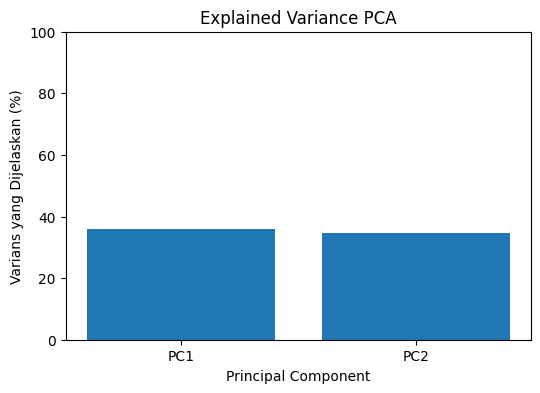

In [75]:
# Membuat grafik persentase varians PCA
plt.figure(figsize=(6, 4))

plt.bar(['PC1', 'PC2'], varians_pca * 100)

plt.title('Explained Variance PCA')
plt.xlabel('Principal Component')
plt.ylabel('Varians yang Dijelaskan (%)')

plt.ylim(0, 100)
plt.show()

# 5. Hasil Akhir Preprocessing
## 5.1 Menyimpan Dataset Bersih

In [76]:
# Menyimpan dataset hasil preprocessing
data.to_csv(
    'dataset_perpustakaan.csv',
    index=False
)

print("Dataset berhasil disimpan!")
print("Jumlah baris:", data.shape[0])
print("Jumlah kolom:", data.shape[1])

Dataset berhasil disimpan!
Jumlah baris: 145
Jumlah kolom: 21


## 5.2 Validasi Akhir Dataset

In [77]:
# Memeriksa kualitas akhir dataset
print("Jumlah baris:", len(data))
print("Jumlah kolom:", len(data.columns))
print("Total missing value:", data.isnull().sum().sum())
print("Total duplikat:", data.duplicated().sum())
print("ID peminjaman unik:", data['ID_Peminjaman'].is_unique)

# Memeriksa konsistensi denda dan status
print("Denda tidak konsisten:",
      (data['Denda_Rp'] != data['Keterlambatan_Hari'] * 1000).sum())

print("Status tidak konsisten:",
      (data['Status_Pengembalian'] != np.where(
          data['Keterlambatan_Hari'] > 0,
          'Terlambat',
          'Tepat Waktu'
      )).sum())

Jumlah baris: 145
Jumlah kolom: 21
Total missing value: 0
Total duplikat: 0
ID peminjaman unik: True
Denda tidak konsisten: 0
Status tidak konsisten: 0


In [78]:
# Memeriksa tanggal kembali yang lebih awal dari tanggal pinjam
tanggal_tidak_valid = data[
    data['Tanggal_Kembali'] < data['Tanggal_Pinjam']
]

print("Jumlah tanggal tidak valid:", len(tanggal_tidak_valid))

tanggal_tidak_valid[
    ['ID_Peminjaman', 'Tanggal_Pinjam', 'Tanggal_Kembali']
]

Jumlah tanggal tidak valid: 0


,ID_Peminjaman,Tanggal_Pinjam,Tanggal_Kembali
